[1.         0.88794508 0.77649827 0.66555879 0.55503691 0.44486711
 0.33492929 0.22490078 0.11425988 0.         0.10796234 0.21954366
 0.33173738 0.44402178 0.5560742  0.66777454 0.77905728 0.8898327
 1.        ]
[ 1.10240140e-17  1.93952007e-03  2.21438415e-03  7.47762949e-04
 -2.34757425e-03 -6.75826688e-03 -1.20648926e-02 -1.72031403e-02
 -1.98048088e-02  0.00000000e+00  4.46978613e-02  6.05952105e-02
  6.75619459e-02  6.79662685e-02  6.29791614e-02  5.34479497e-02
  3.97307724e-02  2.19403990e-02 -1.10240140e-17]


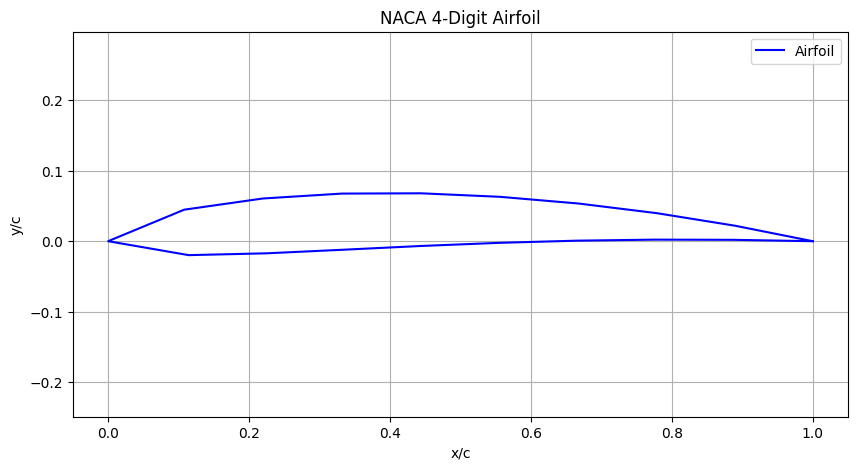

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

m = np.random.uniform(0.01, 0.06)
p = np.random.uniform(0.20, 0.60)
t = np.random.uniform(0.08, 0.18)
def naca(n):
  n=int(n/2)
  x = np.linspace(0, 1, n)

  yt = 5 * t * ( 0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3 - 0.1036 * x**4)

  yc = np.zeros(n)
  dyc_dx = np.zeros(n)

  for i in range(len(x)):

      if x[i] <= p:

          yc[i] = (m / p**2) * (2 * p * x[i] - x[i]**2)
          dyc_dx[i] = (2 * m / p**2) * (p - x[i])

      else:

          yc[i] = (m / (1 - p)**2) * ((1 - 2 * p)+ 2 * p * x[i]- x[i]**2)
          dyc_dx[i] = (2 * m / (1 - p)**2) * ( p - x[i])

  theta = np.arctan(dyc_dx)

  xu = x - yt * np.sin(theta)
  yu = yc + yt * np.cos(theta)

  xl = x + yt * np.sin(theta)
  yl = yc - yt * np.cos(theta)

  xl1=np.flip(xl)
  xcurve=np.concatenate((xl1 , xu[1:]))
  yl1=np.flip(yl)
  ycurve=np.concatenate((yl1 , yu[1:]))
  print(xcurve)
  print(ycurve)

  return xcurve,ycurve

xcurve , ycurve =naca(20)

plt.figure(figsize=(10, 5))

plt.plot(xcurve, ycurve, 'b-', label='Airfoil')

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('NACA 4-Digit Airfoil')

plt.axis('equal')
plt.grid()
plt.legend()
plt.show()


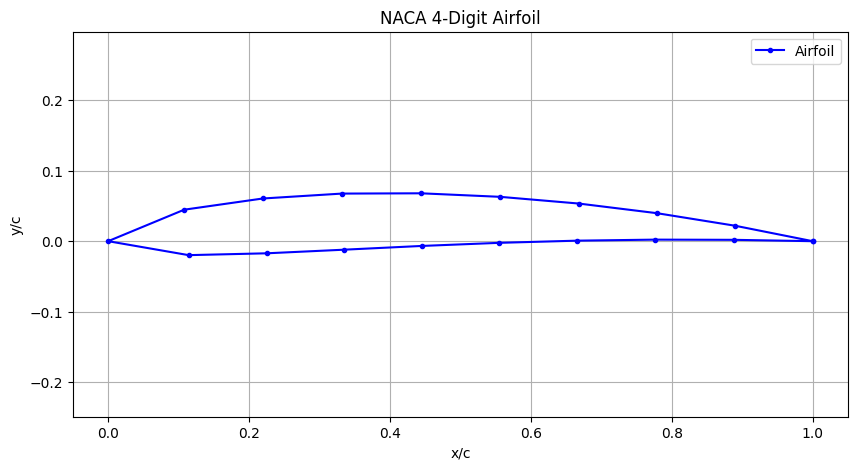

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(xcurve, ycurve, 'b-o' , markersize=3 ,label='Airfoil')

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('NACA 4-Digit Airfoil')

plt.axis('equal')
plt.grid()
plt.legend()
plt.show()


<Figure size 1000x500 with 0 Axes>

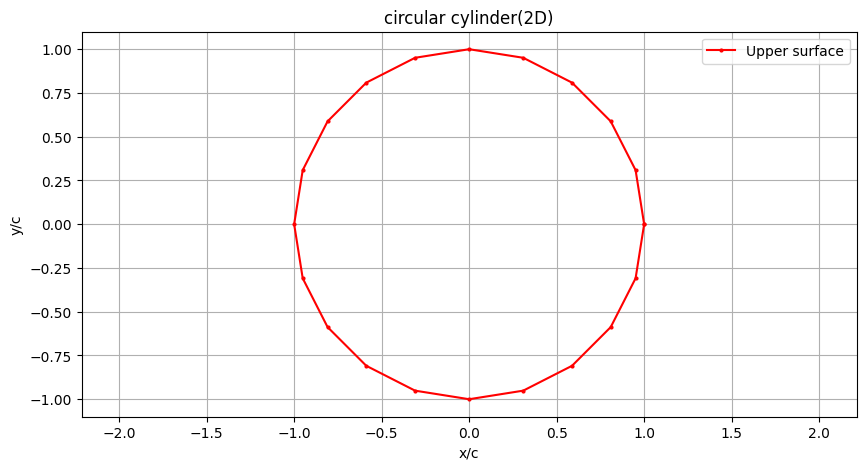

In [ ]:
def cylinder(r,n):
  theta=np.linspace(2*np.pi, 0, n+1)
  r=1
  a=r*np.cos(theta)
  b=r*np.sin(theta)
  plt.figure(figsize=(10, 5))
  return a,b

xb,yb=cylinder(1,20)

plt.figure(figsize=(10, 5))
plt.plot(xb, yb, 'r-o', label='Upper surface' , markersize=2)

plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title('circular cylinder(2D)')
plt.axis('equal')
plt.grid()
plt.legend()
plt.show()

In [ ]:
##DEFINE PANEL GEOMETRY

def geometry(xb , yb):
  dx=np.diff(xb)
  dy=np.diff(yb)

  ##Finding midpoint
  xc=0.5*(xb[:-1] + xb[1:])
  yc=0.5*(yb[:-1] + yb[1:])

  ##calculating length  of panel
  s=np.sqrt(dx**2 + dy**2)
  print("length of panel:",s)

  ##calculating angle
  theta=np.arctan2(dy,dx)
  print("angle:",theta)


  return xc,yc,dx,dy,s,theta

xc,yc,dx,dy,s,theta=geometry(xb,yb)

length of panel: [0.31286893 0.31286893 0.31286893 0.31286893 0.31286893 0.31286893
 0.31286893 0.31286893 0.31286893 0.31286893 0.31286893 0.31286893
 0.31286893 0.31286893 0.31286893 0.31286893 0.31286893 0.31286893
 0.31286893 0.31286893]
angle: [-1.72787596 -2.04203522 -2.35619449 -2.67035376 -2.98451302  2.98451302
  2.67035376  2.35619449  2.04203522  1.72787596  1.41371669  1.09955743
  0.78539816  0.4712389   0.15707963 -0.15707963 -0.4712389  -0.78539816
 -1.09955743 -1.41371669]


In [ ]:
## Defining unit tangent vectors and normal vectors

nx=-np.sin(theta)      ##normal components
ny=np.cos(theta)
print("unit tangent vector:",nx)
print("unit normal vector:",ny)

tx=np.cos(theta)
ty=np.sin(theta)                    ##tangential components
print("unit tangent vector:",tx)
print("unit normal vector:",ty)

unit tangent vector: [ 0.98768834  0.89100652  0.70710678  0.4539905   0.15643447 -0.15643447
 -0.4539905  -0.70710678 -0.89100652 -0.98768834 -0.98768834 -0.89100652
 -0.70710678 -0.4539905  -0.15643447  0.15643447  0.4539905   0.70710678
  0.89100652  0.98768834]
unit normal vector: [-0.15643447 -0.4539905  -0.70710678 -0.89100652 -0.98768834 -0.98768834
 -0.89100652 -0.70710678 -0.4539905  -0.15643447  0.15643447  0.4539905
  0.70710678  0.89100652  0.98768834  0.98768834  0.89100652  0.70710678
  0.4539905   0.15643447]
unit tangent vector: [-0.15643447 -0.4539905  -0.70710678 -0.89100652 -0.98768834 -0.98768834
 -0.89100652 -0.70710678 -0.4539905  -0.15643447  0.15643447  0.4539905
  0.70710678  0.89100652  0.98768834  0.98768834  0.89100652  0.70710678
  0.4539905   0.15643447]
unit normal vector: [-0.98768834 -0.89100652 -0.70710678 -0.4539905  -0.15643447  0.15643447
  0.4539905   0.70710678  0.89100652  0.98768834  0.98768834  0.89100652
  0.70710678  0.4539905   0.15643447 -0

In [ ]:
##defining vortex_panel_method_0

def vortex_panel_method_0(xb, yb, alpha_deg, v_inf=1.0):
  alpha_deg=0.0       ##This is defined for circular cylinder
  alpha=np.radians(alpha_deg)

  vx=v_inf*np.cos(alpha)
  vy=v_inf*np.sin(alpha)
  print("vortex velocity(x):", vx )
  print("vortex velocity(y):", vy )
  return vx,vy
vx,vy=vortex_panel_method_0(xb,yb,0.0)

##calculating influence coefficient

N = len(s)  ##Stores data for total no. of panels

# Influence coefficients
u = np.zeros((N, N)) ##data for x component of vel
v = np.zeros((N, N))  ##data for y component of vel

for i in range(N):

    for j in range(N):

        # Self influence (principal value)
        if i == j:
            u[i,j] = 0.0
            v[i,j] = 0.0

        else:
          X = (xc[i] - xb[j])*np.cos(theta[j]) + \
                (yc[i] - yb[j])*np.sin(theta[j])
                                                                ## distances from panel midpoint[i] to the edges of the panel[j
          Y = -(xc[i] - xb[j])*np.sin(theta[j]) + \
                (yc[i] - yb[j])*np.cos(theta[j])

          angle1 = np.arctan2(Y, X-s[j])
          angle2 = np.arctan2(Y, X)

          diff_angle = angle2 - angle1
          diff_angle = (diff_angle + np.pi) % (2 * np.pi) - np.pi  ## KEEPING ANGLE BETWEEN [-2PI TO PI (CW)]

          u[i,j] = -diff_angle / (2 * np.pi)

          r1 = X**2 + Y**2
          r2 = (X-s[j])**2 + Y**2
          v[i,j] =(1/(2*np.pi))*np.log(r1/r2)
          print("influence coefficient(x):",u[i,j])
          print("influence coefficient(y):",v[i,j])




vortex velocity(x): 1.0
vortex velocity(y): 0.0
influence coefficient(x): -0.033394761765933256
influence coefficient(y): -0.34619889984820956
influence coefficient(x): -0.026725485953232764
influence coefficient(y): -0.1572575387163026
influence coefficient(x): -0.025771129074640204
influence coefficient(y): -0.0991068731354629
influence coefficient(x): -0.025454420948219297
influence coefficient(y): -0.06922470539697971
influence coefficient(x): -0.025312258108857396
influence coefficient(y): -0.0502029778246633
influence coefficient(x): -0.02523784856172519
influence coefficient(y): -0.03643959573413941
influence coefficient(x): -0.02519576511075994
influence coefficient(y): -0.025541237306261923
influence coefficient(x): -0.02517166121742527
influence coefficient(y): -0.016282326072144287
influence coefficient(x): -0.02515908519063772
influence coefficient(y): -0.007935642470949106
influence coefficient(x): -0.025155168137137494
influence coefficient(y): 0.0
influence coefficient(x

In [ ]:
## transform these local induced velocities system to global system

A = np.zeros((N, N))

for i in range(N):

    for j in range(N):

        # Transform local velocity into global coordinates
        ux = u[i,j]*np.cos(theta[j]) - v[i,j]*np.sin(theta[j])

        uy = u[i,j]*np.sin(theta[j]) + v[i,j]*np.cos(theta[j])



